In [7]:
using Plots

# Basic

## Floating number
- We should not expect that two mathematically equivalent results will be equal when computed in floating point, only that they be relatively close together.

- *Subtractive cancellation* is a loss of accuracy that occurs when two numbers add or subtract to give a result that is much smaller in magnitude. It is one of the most common mechanisms introducing dramatic growth of errors in floating-point computation.

- *Estimating errors*. whenever the data x is perturbed by a small amount, we expect that relative perturbation to be magnified by a factor of *condition number* in the result.
    - If k_f = 10^d, then we expect to lose up to d decimal digits of accuracy in computing f(x) from x.

    - In practice, k < 1 is no different from k = 1, caused by rounding errer.

- *Polynomial root*. Roots of polynomial are ill-conditional with respect to change in coefficients when they are close to each other.

Double precision

In [3]:
# spacing between two floating point values
eps()

2.220446049250313e-16

In [ ]:
# the total num of digits for floating point number
log2(eps())

-52.0

In [5]:
@show floatmin(), floatmax()

(floatmin(), floatmax()) = (2.2250738585072014e-308, 1.7976931348623157e308)


(2.2250738585072014e-308, 1.7976931348623157e308)

In [13]:
# 1 sign, 11 binary bits
2.0^1024, 2.0^1023

(Inf, 8.98846567431158e307)

In [8]:
e = eps() / 2

1.1102230246251565e-16

- no double-precision number between [1, 1 + eps];
- Numbers between [-1, 1] are reprenented using doule-precision.

In [14]:
# epsilon of machine is e, difference smaller than eps is 0
(1.0 + e) - 1.0, 1.0 + (e - 1.0)

(0.0, 1.1102230246251565e-16)

In [15]:
for x in (0.5, 1.0, 2.0, 4.0)
    println(
        "x = $x, previous = $(prevfloat(x)), ",
        "next = $(nextfloat(x)), spacing above = $(nextfloat(x) - x)"
    )
end

x = 0.5, previous = 0.49999999999999994, next = 0.5000000000000001, spacing above = 1.1102230246251565e-16
x = 1.0, previous = 0.9999999999999999, next = 1.0000000000000002, spacing above = 2.220446049250313e-16
x = 2.0, previous = 1.9999999999999998, next = 2.0000000000000004, spacing above = 4.440892098500626e-16
x = 4.0, previous = 3.9999999999999996, next = 4.000000000000001, spacing above = 8.881784197001252e-16


In [16]:
nextfloat(1/10)

0.10000000000000002

In [18]:
nextfloat(floatmax()), prevfloat(floatmin())

(Inf, 2.225073858507201e-308)

In [19]:
ϵ = 1e-6
a, b, c = 1/3, (-2-ϵ)/3, (1+ϵ)/3

d = sqrt(b^2 - 4*a*c)
r₁ = (-b - d)/(2a)
r₂ = (-b + d)/(2a)
(r₁, r₂)

(0.9999999998251499, 1.0000010001748503)

In [20]:
abs(r₂ - (1 + ϵ)) / (1 + ϵ), abs(r₂ - (1 + ϵ)) / r₂

(1.748501815656639e-10, 1.7485018153509132e-10)

In [21]:
eps() / ϵ

2.220446049250313e-10

In [1]:
bitstring(1.0)

"0011111111110000000000000000000000000000000000000000000000000000"

In [2]:
length(bitstring(1.0))

64

In [5]:
string(-1022, base=2)

"-1111111110"

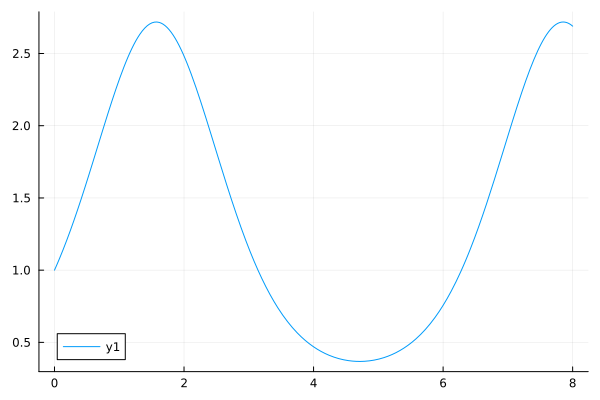

In [9]:
plot(x -> exp(sin(x)), 0, 8)

In [ ]:
ϵ = 1e-20
A = [ϵ 1; 1 1]; b = [1.0, 2.0]

# bad pivot = ϵ
m = A[2, 1] / A[1, 1]   # huge since small ϵ
u22 = A[2, 2] - m*A[1, 2]
c2 = b[2] - m*b[1]
y = c2/u22 
x   = (b[1] - A[1,2]*y)/A[1,1] # here is error happens
println("no pivoting:      x = $x, y = $y")

no pivoting:      x = 0.0, y = 1.0


In [13]:
# Good: partial pivoting (Julia's backslash uses LU with partial pivoting)
println("partial pivoting: ", A \ b) # [1.0, 1.0]  ← correct

partial pivoting: [1.0, 1.0]


In [24]:
cond(A)

2.6180339887498953

In [15]:
using LinearAlgebra

In [17]:
F = lu(A)
F.p, F.L, F.U

([2, 1], [1.0 0.0; 1.0e-20 1.0], [1.0 1.0; 0.0 1.0])

In [18]:
using Polynomials

In [19]:
r = [-2.0, -1, 1, 1, 3, 6]
p = fromroots(r)

Polynomial(36.0 - 36.0*x - 43.0*x^2 + 44.0*x^3 + 6.0*x^4 - 8.0*x^5 + 1.0*x^6)

In [20]:
r̃ = sort(roots(p))

6-element Vector{Float64}:
 -1.9999999999999993
 -1.0000000000000002
  0.9999999876457746
  1.000000012354224
  3.0000000000000036
  5.999999999999993

In [ ]:
@. abs(r - r̃)/r    # forward error

6-element Vector{Float64}:
 -3.3306690738754696e-16
 -2.220446049250313e-16
  1.235422542045228e-8
  1.2354224088184651e-8
  1.1842378929335002e-15
  1.1842378929335002e-15

In [22]:
p̃ = fromroots(r̃)

Polynomial(35.99999999999994 - 35.99999999999999*x - 42.999999999999936*x^2 + 43.99999999999997*x^3 + 6.000000000000001*x^4 - 7.999999999999996*x^5 + 1.0*x^6)

In [23]:
c, c̃ = coeffs(p), coeffs(p̃)
@. abs(c - c̃)/c

7-element Vector{Float64}:
  1.578983857244667e-15
 -1.9737298215558337e-16
 -1.4871824701955586e-15
  6.459479416000911e-16
  1.4802973661668753e-16
 -5.551115123125783e-16
  0.0

In [25]:
δ = 1e-4
A = [1 1; 1 1+δ]
cond(A)

40002.000074915224

In [27]:
eigvals(A)

2-element Vector{Float64}:
 4.999875000000209e-5
 2.00005000125

In [29]:
b1 = [2, 2+δ]; x1 = A \ b1
b2 = [2, 2+2*δ]; x2 = A \ b2

rel_in = norm(b2-b1)/norm(b1)
rel_out = norm(x2 - x1)/norm(x1)

rel_out/rel_in

28284.978363084814

In [30]:
log10(cond(A))

4.602081706322549

In [31]:
year = [1982,2000,2010,2015]; 
pop = [1008.18, 1262.64, 1337.82, 1374.62];

In [33]:
t = year .- 1980
y = pop

4-element Vector{Float64}:
 1008.18
 1262.64
 1337.82
 1374.62

In [34]:
# an interpolating cubic polynomial
v = [ t[i]^j for i in 1:4, j in 0:3]


4×4 Matrix{Int64}:
 1   2     4      8
 1  20   400   8000
 1  30   900  27000
 1  35  1225  42875

In [35]:
c = v \ y

4-element Vector{Float64}:
 962.2387878787875
  24.127754689754774
  -0.5922620490620537
   0.00684386724386731

In [36]:
y - v*c

4-element Vector{Float64}:
 0.0
 0.0
 2.2737367544323206e-13
 0.0

In [38]:
p = Polynomial(c)
p(2005 - 1980)

1302.2043001443

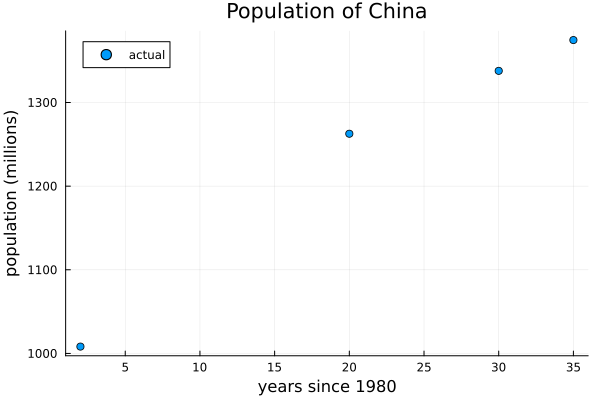

In [ ]:
scatter(t,y, label="actual", legend=:topleft,
    xlabel="years since 1980", ylabel="population (millions)", 
    title="Population of China")


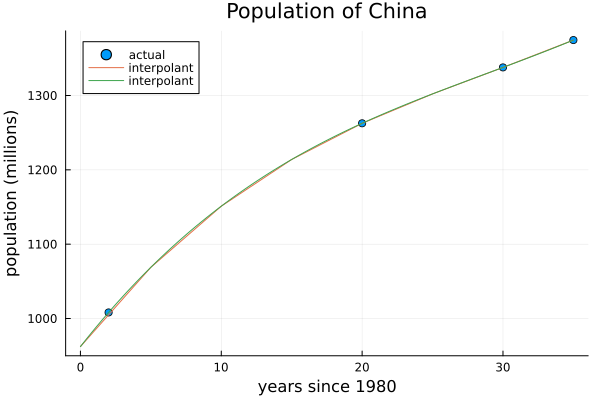

In [46]:
tt = range(0, 35, length=500)
yy = p.(tt)
plot!(tt,yy,label="interpolant")

In [47]:
s = range(-1, 1, length=5)

-1.0:0.5:1.0

In [64]:
A = [ 1 2 3 4 5; 50 40 30 20 10
    π sqrt(2) exp(1) (1+sqrt(5))/2 log(3) ]

3×5 Matrix{Float64}:
  1.0       2.0       3.0       4.0       5.0
 50.0      40.0      30.0      20.0      10.0
  3.14159   1.41421   2.71828   1.61803   1.09861

In [49]:
A[2, end-1]

20.0

In [53]:
A[1:2, end-2:end]

2×3 Matrix{Float64}:
  3.0   4.0   5.0
 30.0  20.0  10.0

In [55]:
A[:, 1:2:end]

3×3 Matrix{Float64}:
  1.0       3.0       5.0
 50.0      30.0      10.0
  3.14159   2.71828   1.09861

In [52]:
x = [1, 2, 3, 4]
size(x)

(4,)

In [57]:
B = diagm([-1, 0, 5])

3×3 Matrix{Int64}:
 -1  0  0
  0  0  0
  0  0  5

In [ ]:
BA = B*A

3×5 Matrix{Float64}:
 -1.0    -2.0      -3.0     -4.0      -5.0
  0.0     0.0       0.0      0.0       0.0
 15.708   7.07107  13.5914   8.09017   5.49306

In [65]:
A

3×5 Matrix{Float64}:
  1.0       2.0       3.0       4.0       5.0
 50.0      40.0      30.0      20.0      10.0
  3.14159   1.41421   2.71828   1.61803   1.09861

In [66]:
C = -A

3×5 Matrix{Float64}:
  -1.0       -2.0       -3.0       -4.0       -5.0
 -50.0      -40.0      -30.0      -20.0      -10.0
  -3.14159   -1.41421   -2.71828   -1.61803   -1.09861

In [67]:
elementwise = A .*C

3×5 Matrix{Float64}:
    -1.0        -4.0    -9.0       -16.0       -25.0
 -2500.0     -1600.0  -900.0      -400.0      -100.0
    -9.8696     -2.0    -7.38906    -2.61803    -1.20695

In [68]:
x

4-element Vector{Int64}:
 1
 2
 3
 4

In [69]:
two_to_two = x .^2

4-element Vector{Int64}:
  1
  4
  9
 16

In [70]:
two_to_x = 2 .^ x

4-element Vector{Int64}:
  2
  4
  8
 16

In [71]:
show(cos.(π*x))

[-1.0, 1.0, -1.0, 1.0]

In [86]:
A = [2 1 1 0; 0 -1 4 1; 2 2 0 -2; 1 3 -1 5]
B = [3 -1 0 2; 7 1 0 2]
A

4×4 Matrix{Int64}:
 2   1   1   0
 0  -1   4   1
 2   2   0  -2
 1   3  -1   5

In [87]:
u = [2,-1, 3, 1]
v = [π, ℯ] #\euler

2-element Vector{Float64}:
 3.141592653589793
 2.718281828459045

In [77]:
B*A

2×4 Matrix{Int64}:
  8  10  -3   9
 16  12   9  11

In [78]:
v'*B

1×4 adjoint(::Vector{Float64}) with eltype Float64:
 28.4528  -0.423311  0.0  11.7197

In [79]:
B*u

2-element Vector{Int64}:
  9
 15

In [90]:
# [u A*u A^2 * u A^3 *u]
[u A*u A^2 * u A^3 * u]

4×4 Matrix{Int64}:
  2   6   26   77
 -1  14  -13  218
  3   0   38  -80
  1   1   53  214

In [89]:
stack(A^k * u for k in 0:3)

4×4 Matrix{Int64}:
  2   6   26   77
 -1  14  -13  218
  3   0   38  -80
  1   1   53  214

In [91]:
A'

4×4 adjoint(::Matrix{Int64}) with eltype Int64:
 2   0   2   1
 1  -1   2   3
 1   4   0  -1
 0   1  -2   5

In [93]:
size(u, 1)

4

In [114]:
# forwardsub
function forwardSub(L, b)
    n = size(L, 1)
    x = zeros(n)
    x[1] = b[1] / L[1, 1]
    for i in 2:n
        s = sum(L[i, j] * x[j] for j in 1:i-1)
        x[i] = (b[i] - s) / L[i, i]
    end
    return x
end

forwardSub (generic function with 1 method)

In [95]:
L = [4 0 0 0; 3 -1 0 0; -1 0 3 0; 1 -1 -1 2]
b = [8, 5, 0, 1]

4-element Vector{Int64}:
 8
 5
 0
 1

In [96]:
x = forwardSub(L, b)
x

4-element Vector{Float64}:
 2.0
 1.0
 0.6666666666666666
 0.3333333333333333

In [104]:
[i for i in 5:-1:1]

5-element Vector{Int64}:
 5
 4
 3
 2
 1

In [118]:
# backSub
function backSub(U, b)
    n = size(U, 1)
    x = zeros(n)
    x[n] = b[n] / U[n, n]
    for i in n-1:-1:1
        s = sum(U[i, j]*x[j] for j in i+1:n)
        x[i] = (b[i] - s) / U[i, i]
    end
    return x
end

backSub (generic function with 1 method)

In [97]:
A = rand(1.:9., 5, 5)
L = tril(A)

5×5 Matrix{Float64}:
 4.0  0.0  0.0  0.0  0.0
 4.0  5.0  0.0  0.0  0.0
 3.0  2.0  7.0  0.0  0.0
 6.0  4.0  6.0  3.0  0.0
 1.0  8.0  9.0  6.0  1.0

In [98]:
b = ones(5)
x = forwardSub(L, b)

5-element Vector{Float64}:
  0.25
  0.0
  0.03571428571428571
 -0.23809523809523805
  1.857142857142857

In [99]:
b - L*x

5-element Vector{Float64}:
 0.0
 0.0
 0.0
 0.0
 0.0

In [109]:
α = 0.3
β = 1e12
U = diagm(0=>ones(5), 1=>[-1, -1, -1, -1])
U[1, [4, 5]] = [α - β, β]
U

5×5 Matrix{Float64}:
 1.0  -1.0   0.0  -1.0e12   1.0e12
 0.0   1.0  -1.0   0.0      0.0
 0.0   0.0   1.0  -1.0      0.0
 0.0   0.0   0.0   1.0     -1.0
 0.0   0.0   0.0   0.0      1.0

In [110]:
b = [α, 0, 0, 0, 1]

5-element Vector{Float64}:
 0.3
 0.0
 0.0
 0.0
 1.0

In [111]:
x = backSub(U, b)

5-element Vector{Float64}:
 0.999951171875
 1.0
 1.0
 1.0
 1.0

In [112]:
x - ones(5)

5-element Vector{Float64}:
 -4.882812499995559e-5
  0.0
  0.0
  0.0
  0.0

In [113]:
L₁ = [-2 0 0; 1 -1 0; 3 2 1]
b₁ = [-4, 2, 1]

3-element Vector{Int64}:
 -4
  2
  1

In [115]:
x₁ = forwardSub(L₁, b₁)

3-element Vector{Float64}:
  2.0
 -0.0
 -5.0

In [116]:
L₂ = [4 0 0 0; 1 -2 0 0; -1 4 4 0; 2 -5 5 1]
b₂ = [-4, 1, -3, 5]

4-element Vector{Int64}:
 -4
  1
 -3
  5

In [117]:
x₂ = forwardSub(L₂, b₂)

4-element Vector{Float64}:
 -1.0
 -1.0
  0.0
  2.0

In [119]:
U₁ = [3 2 1; 0 1 -1; 0 0 2]
b₁ = [1, 2, -4]

3-element Vector{Int64}:
  1
  2
 -4

In [120]:
x₁ = backSub(U₁, b₁)

3-element Vector{Float64}:
  1.0
  0.0
 -2.0

In [121]:
U₂ = [3 1 0; 0 -1 -2; 0 0 3]
b₂ = [1, 1, 6]
x₂ = backSub(U₂, b₂)

3-element Vector{Float64}:
  2.0
 -5.0
  2.0

In [122]:
b₂ - U₂ * x₂

3-element Vector{Float64}:
 0.0
 0.0
 0.0

In [129]:
α = 0.1
β = 1e12

1.0e12

In [130]:
A = diagm(0=>ones(5), 1=>[-1, -1, -1, -1])
A[1, [4,5]] = [α - β, β]
b = [α, 0, 0, 0, 1]

5-element Vector{Float64}:
 0.1
 0.0
 0.0
 0.0
 1.0

In [131]:
x = backSub(A, b)

5-element Vector{Float64}:
 1.0000244140625
 1.0
 1.0
 1.0
 1.0

In [132]:
abs.(x - ones(5))

5-element Vector{Float64}:
 2.4414062500088818e-5
 0.0
 0.0
 0.0
 0.0

## LU


In [133]:
L = tril(rand(1:9, 3, 3))

3×3 Matrix{Int64}:
 4  0  0
 6  6  0
 8  1  1

In [134]:
U = triu(rand(1:9, 3, 3))

3×3 Matrix{Int64}:
 9  7  8
 0  7  7
 0  0  4

In [136]:
L[:,1] * U[1,:]'

3×3 Matrix{Int64}:
 36  28  32
 54  42  48
 72  56  64

In [137]:
L[:, 2:2] * U[2:2, :]

3×3 Matrix{Int64}:
 0   0   0
 0  42  42
 0   7   7

In [139]:
L[:, 3:3] * U[3:3,:]

3×3 Matrix{Int64}:
 0  0  0
 0  0  0
 0  0  4

In [140]:
A = [
     2    0    4     3 
    -4    5   -7   -10 
     1   15    2   -4.5
    -2    0    2   -13
    ];
L = diagm(ones(4))
U = zeros(4, 4)

4×4 Matrix{Float64}:
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0

In [141]:
U[1,:] = A[1,:]
U

4×4 Matrix{Float64}:
 2.0  0.0  4.0  3.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0

In [143]:
L[:, 1] = A[:, 1] ./A[1, 1]
L

4×4 Matrix{Float64}:
  1.0  0.0  0.0  0.0
 -2.0  1.0  0.0  0.0
  0.5  0.0  1.0  0.0
 -1.0  0.0  0.0  1.0

In [144]:
A₂ = A - L[:, 1:1]*U[1:1,:]

4×4 Matrix{Float64}:
 0.0   0.0  0.0    0.0
 0.0   5.0  1.0   -4.0
 0.0  15.0  0.0   -6.0
 0.0   0.0  6.0  -10.0

In [145]:
U[2,:] = A₂[2,:]
U

4×4 Matrix{Float64}:
 2.0  0.0  4.0   3.0
 0.0  5.0  1.0  -4.0
 0.0  0.0  0.0   0.0
 0.0  0.0  0.0   0.0

In [146]:
L[:, 2] = A₂[:, 2] ./ A₂[2, 2]
L

4×4 Matrix{Float64}:
  1.0  0.0  0.0  0.0
 -2.0  1.0  0.0  0.0
  0.5  3.0  1.0  0.0
 -1.0  0.0  0.0  1.0

In [147]:
A₃ = A₂ - L[:, 2:2] * U[2:2, :]
A₃

4×4 Matrix{Float64}:
 0.0  0.0   0.0    0.0
 0.0  0.0   0.0    0.0
 0.0  0.0  -3.0    6.0
 0.0  0.0   6.0  -10.0

In [148]:
U[3,:] = A₃[3,:]
L[:,3] = A₃[:,3]/U[3,3]
A₄ = A₃ - L[:,3]*U[3,:]'

4×4 Matrix{Float64}:
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  2.0

In [149]:
U[4,4] = A₄[4,4]

2.0

In [150]:
L

4×4 Matrix{Float64}:
  1.0  0.0  -0.0  0.0
 -2.0  1.0  -0.0  0.0
  0.5  3.0   1.0  0.0
 -1.0  0.0  -2.0  1.0

In [151]:
U

4×4 Matrix{Float64}:
 2.0  0.0   4.0   3.0
 0.0  5.0   1.0  -4.0
 0.0  0.0  -3.0   6.0
 0.0  0.0   0.0   2.0

In [152]:
A - L*U

4×4 Matrix{Float64}:
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0

In [154]:
function lufactor(A)
    n = size(A, 1)
    L = diagm(ones(n))
    U = zeros(n, n)
    Aₖ = copy(float(A))

    for k in 1:n-1
        U[k,:] = Aₖ[k,:]
        L[:, k] = Aₖ[:, k] / U[k, k]
        Aₖ = Aₖ - L[:, k:k] * U[k:k, :]
    end
    U[n,n] = Aₖ[n,n]
    return LowerTriangular(L),UpperTriangular(U)
end

lufactor (generic function with 1 method)

In [155]:
A = [2 0 4 3; -4 5 -7 -10; 1 15 2 -4.5; -2 0 2 -13];
b = [4,9,9,4];

In [156]:
L, U = lufactor(A)

([1.0 0.0 0.0 0.0; -2.0 1.0 0.0 0.0; 0.5 3.0 1.0 0.0; -1.0 0.0 -2.0 1.0], [2.0 0.0 4.0 3.0; 0.0 5.0 1.0 -4.0; 0.0 0.0 -3.0 6.0; 0.0 0.0 0.0 2.0])

In [157]:
z = forwardSub(L, b)
x = backSub(U, z)

4-element Vector{Float64}:
 192.66666666666666
 -15.533333333333335
 -65.33333333333333
 -40.0

In [158]:
b - A*x

4-element Vector{Float64}:
  0.0
 -5.684341886080802e-14
  2.842170943040401e-14
  0.0

In [170]:
A = diagm(0=>ones(4), -1=>ones(4), 4=>[1e20])
x̂ = [0, 1/3, 2/3, 1, 4/3]

5-element Vector{Float64}:
 0.0
 0.3333333333333333
 0.6666666666666666
 1.0
 1.3333333333333333

In [171]:
b = A*x̂

5-element Vector{Float64}:
 1.3333333333333333e20
 0.3333333333333333
 1.0
 1.6666666666666665
 1.0

In [172]:
L, U = lufactor(A)
z = forwardSub(L, b)
x = backSub(U, z)

5-element Vector{Float64}:
 0.0
 0.0
 0.0
 0.0
 1.3333333333333333

In [173]:
x - x̂

5-element Vector{Float64}:
  0.0
 -0.3333333333333333
 -0.6666666666666666
 -1.0
  0.0

In [174]:
A = diagm(0=>ones(6), 1=>ones(5), 3=>ones(3), -3=>ones(3), -4=>ones(2))

6×6 Matrix{Float64}:
 1.0  1.0  0.0  1.0  0.0  0.0
 0.0  1.0  1.0  0.0  1.0  0.0
 0.0  0.0  1.0  1.0  0.0  1.0
 1.0  0.0  0.0  1.0  1.0  0.0
 1.0  1.0  0.0  0.0  1.0  1.0
 0.0  1.0  1.0  0.0  0.0  1.0

In [175]:
L, U = lufactor(A)
L

6×6 LowerTriangular{Float64, Matrix{Float64}}:
 1.0    ⋅    ⋅     ⋅    ⋅    ⋅ 
 0.0   1.0   ⋅     ⋅    ⋅    ⋅ 
 0.0   0.0  1.0    ⋅    ⋅    ⋅ 
 1.0  -1.0  1.0   1.0   ⋅    ⋅ 
 1.0   0.0  0.0   1.0  1.0   ⋅ 
 0.0   1.0  0.0  -0.0  1.0  1.0

In [176]:
U

6×6 UpperTriangular{Float64, Matrix{Float64}}:
 1.0  1.0  0.0   1.0   0.0   0.0
  ⋅   1.0  1.0   0.0   1.0   0.0
  ⋅    ⋅   1.0   1.0   0.0   1.0
  ⋅    ⋅    ⋅   -1.0   2.0  -1.0
  ⋅    ⋅    ⋅     ⋅   -1.0   2.0
  ⋅    ⋅    ⋅     ⋅     ⋅   -1.0

In [177]:
A - L*U

6×6 Matrix{Float64}:
 0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0

In [179]:
A = randn(5, 5) + 100*I
L, U = lufactor(A)
U

5×5 UpperTriangular{Float64, Matrix{Float64}}:
 97.6175  -0.308947   -0.955808   0.949126  -0.576576
   ⋅      98.9723     -0.439514   0.52072    1.6914
   ⋅        ⋅        100.717     -1.32622    0.89389
   ⋅        ⋅           ⋅        96.8203    -1.54548
   ⋅        ⋅           ⋅          ⋅        99.5893

In [180]:
cond(A)

1.051494233406192